In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
# rng = np.random.default_rng()
# samples = rng.normal(size=N)
# print(samples)

In [ ]:
print(3.6 * np.sqrt(8))
print(5 * np.sqrt(8))

In [ ]:
plt.plot(f, S(f));

from scipy.integrate import quad

m0, error = quad(S, 0, np.inf)

print(m0)
print(Hs**2 / 16)

print(f'Standard deviation of random eta={eta.std():.4f}, m0 (intended variance)={Hs**2 / 16}')
print(f'Mean of random eta={eta.mean():.4f}, intended mean=0')

# Compare the distribution of eta with the theoretical Gaussian distribution
mean_eta = 0
variance_eta = Hs**2 / 16
std_eta = np.sqrt(variance_eta)

fig, ax = plt.subplots(figsize=(8, 5))

eta_bins = np.linspace(-4*std_eta, 4*std_eta, 41)
ax.hist(eta, bins=eta_bins, density=True, alpha=0.6,
        color='steelblue', edgecolor='black', label=r'One Random $\eta$(t) Sample')

eta_range = np.linspace(-3*std_eta, 3*std_eta, 500)
gaussian = (1 / (std_eta*np.sqrt(2*np.pi))) * np.exp(
    -(eta_range - mean_eta)**2 / (2*variance_eta)
)
ax.plot(eta_range, gaussian, 'r-', linewidth=2,
        label=f'Theoretical Gaussian:\n $\mu$={mean_eta}, $\sigma^2$={variance_eta:.1f}=$m_0$')

ax.set_xlim(-4*std_eta, 4*std_eta)
ax.set_xlabel('Free-surface Amplitude, a [m]', fontsize=16)
ax.set_ylabel('PDF', fontsize=16)
ax.set_title(r'Histogram of $\eta$(t) vs. a theoretical Gaussian distribution', fontsize=16)
ax.legend(loc='upper left', fontsize=12)
plt.tight_layout()
plt.show()


<>:205: SyntaxWarning: invalid escape sequence '\e'
<>:320: SyntaxWarning: invalid escape sequence '\m'
<>:320: SyntaxWarning: invalid escape sequence '\s'
<>:205: SyntaxWarning: invalid escape sequence '\e'
<>:320: SyntaxWarning: invalid escape sequence '\m'
<>:320: SyntaxWarning: invalid escape sequence '\s'
C:\Users\Charl\AppData\Local\Temp\ipykernel_7536\277788533.py:205: SyntaxWarning: invalid escape sequence '\e'
  ax[1].set_ylabel(r'$\eta_{2}$ [m]')
C:\Users\Charl\AppData\Local\Temp\ipykernel_7536\277788533.py:320: SyntaxWarning: invalid escape sequence '\m'
  label=f'Theoretical Gaussian:\n $\mu$={mean_eta}, $\sigma^2$={variance_eta:.1f}=$m_0$')
C:\Users\Charl\AppData\Local\Temp\ipykernel_7536\277788533.py:320: SyntaxWarning: invalid escape sequence '\s'
  label=f'Theoretical Gaussian:\n $\mu$={mean_eta}, $\sigma^2$={variance_eta:.1f}=$m_0$')
C:\Users\Charl\AppData\Local\Temp\ipykernel_7536\277788533.py:113: RuntimeWarning: overflow encountered in scalar power
  g * (np.tanh(ki

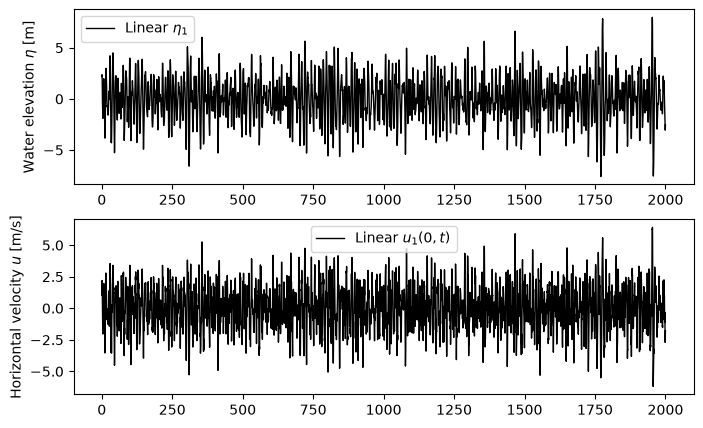

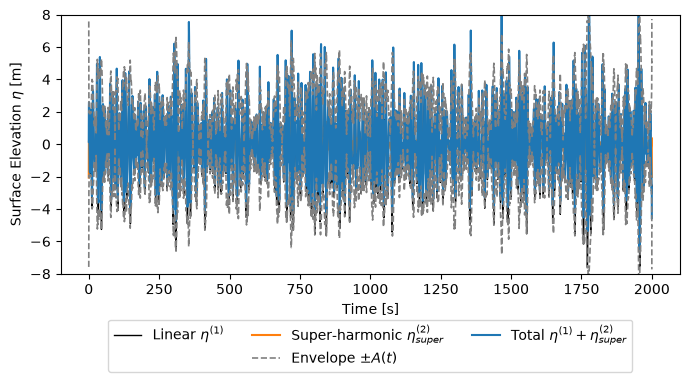

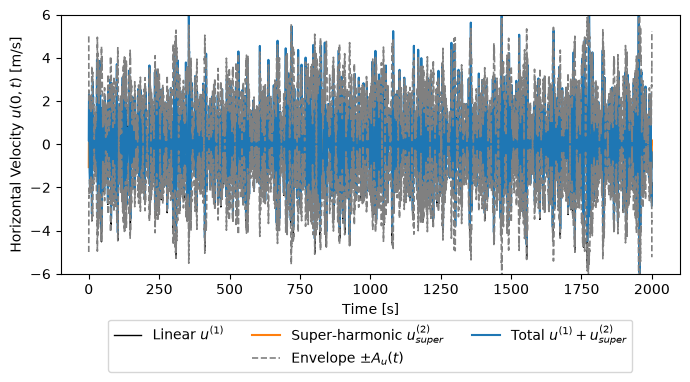

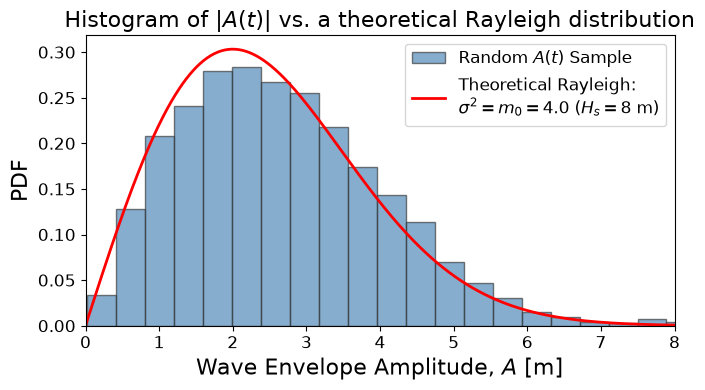

4.0
4.0
Standard deviation of random eta=2.1328, m0 (intended variance)=4.0
Mean of random eta=-0.0007, intended mean=0


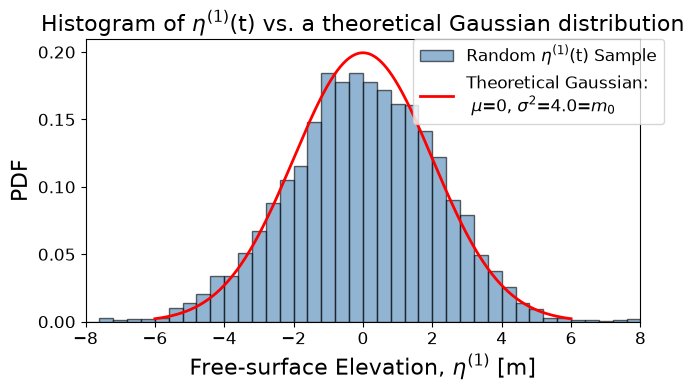

In [100]:
# Specifying period range
minT = 1 # 1second
maxT = 30 # 30 seconds

# Parameters
g = 9.81
h = 30                  # Water depth [m]
N = 10000                 # Number of wave components
f_min = 1 / maxT
f_max = 1 / minT
dt = 0.05
T = 2000                 # Simulation duration [s]
Hs = 8                  # Valid ??? - As given in the problem statement
Tp = 12                 # Given range
fp = 1 / Tp

# Frequency discretization
f = np.linspace(f_min, f_max, N)
df = f[1] - f[0]
omega = 2 * np.pi * f

# Random phases
np.random.seed(42)
phi = np.random.uniform(0, 2*np.pi, N)

# Example wave spectrum (replace with JONSWAP if required)
def S(f):
    return 5/16 * Hs**2 * f ** (-5) * fp**4 * np.exp(-5/4 * (fp/f)**4)

# Wave amplitudes
a = np.sqrt(2 * S(f) * df)

# Solve dispersion relation for each frequency
k = np.zeros(N)

for i in range(N):
    ki = omega[i]**2 / g
    for _ in range(100):
        ki = ki - (
            g * ki * np.tanh(ki*h) - omega[i]**2
        ) / (
            g * (np.tanh(ki*h) + ki*h/np.cosh(ki*h)**2)
        )
    k[i] = ki

# Time vector
t = np.arange(0, T, dt)

# First-order wave field
eta = np.zeros(len(t))
u = np.zeros(len(t))
acheck = 0

for i in range(N):
    phase = omega[i]*t + phi[i]

    eta += a[i] * np.cos(phase)

    u += (
        a[i] * omega[i] *
        np.cosh(k[i]*h) / np.sinh(k[i]*h)
        * np.cos(phase)
    )

    acheck += a[i]

# Plot
#fig, ax = plt.subplots(2, 1, figsize=(12, 7))

#ax[0].plot(t, eta, color='blue')
#ax[0].set_ylabel("Water Elevation η [m]")
#ax[0].set_title("First-order Random Wave Field")

#ax[1].plot(t, u, color='blue')
#ax[1].set_ylabel("Orbital Horizontal Velocity u [m/s]")
#ax[1].set_xlabel("Time [s]")

#plt.tight_layout()
#plt.show()

f = np.linspace(f_min, f_max, N)
superf = f * 2
subf = f / 2
case =1
fn = [f, superf, subf]

# Frequency discretization
f = np.linspace(f_min, f_max, N)
df = fn[case][1] - fn[case][0]
omega = 2 * np.pi * fn[case]

# Random phases
np.random.seed(42)
phi = np.random.uniform(0, 2*np.pi, N)

# Example wave spectrum (replace with JONSWAP if required)
def S(f):
    return 5/16 * Hs**2 * f ** (-5) * fp**4 * np.exp(-5/4 * (fp/f)**4)

# Wave amplitudes
a = np.sqrt(2 * S(fn[case]) * df)


# Solve dispersion relation for each frequency
k = np.zeros(N)

for i in range(N):
    ki = omega[i]**2 / g
    for _ in range(100):
        ki = ki - (
            g * ki * np.tanh(ki*h) - omega[i]**2
        ) / (
            g * (np.tanh(ki*h) + ki*h/np.cosh(ki*h)**2)
        )
    k[i] = ki



H = 2 * a[0]

tsup = np.arange(0, T, dt)
bound_wave = (
    H/2 * np.cos(-omega[0]*tsup)
    + H**2*k[0]/16
    * np.cosh(k[0]*h)/np.sinh(k[0]*h)**3
    * (2 + np.cosh(2*k[0]*h))
    * np.cos(-2*omega[0]*tsup)
)

#fig, ax = plt.subplots(1, 1, figsize=(12, 7))
#plt.plot(tsup, bound_wave, label='Second-order bound wave', color='orange')
#plt.plot(t, eta, label='First order realization', color='blue')
#plt.xlabel('Time [s]')
#plt.ylabel('Water elevation eta [m]')
#plt.legend();


from scipy.signal import hilbert

# --- 1. Solve dispersion relation for the peak frequency fp ---
omega_p = 2 * np.pi * fp
kp = omega_p**2 / g
for _ in range(100):
    kp = kp - (g * kp * np.tanh(kp * h) - omega_p**2) / (
        g * (np.tanh(kp * h) + kp * h / np.cosh(kp * h)**2)
    )

# --- 2. Compute transfer function G(kp * h) ---
kph = kp * h
G = (np.cosh(kph) * (2 + np.cosh(2 * kph))) / (4 * np.sinh(kph)**3)

# --- 3. Extract envelope A(t) and phase theta(t) via Hilbert transform ---
z = hilbert(eta)          # Analytic signal: eta + i * H[eta]
A = np.abs(z)             # Slowly varying wave envelope A(t)
theta = np.angle(z)       # Instantaneous phase theta(t)

# --- 4. Calculate second-order super-harmonic eta_22 ---
eta_22 = G * kp * (A**2) * np.cos(2 * theta)
eta_total = eta + eta_22


# --- 5. Plot results ---

#Plot linear:
fig, axl = plt.subplots(2, 1, figsize=(8,5))


axl[0].plot(t, eta, label=r'Linear $\eta_1$', color='black', linewidth=1)
axl[0].set_ylabel(r'Water elevation $\eta$ [m]')
axl[0].legend()
axl[1].plot(t, u, label=r'Linear $u_1(0,t)$', color='black', linewidth=1)
axl[1].set_ylabel(r'Horizontal velocity $u$ [m/s]')
axl[1].legend()

#Eta plot:

fig, ax = plt.subplots(1, 1, figsize=(7, 4), sharex=True)

l1, =ax.plot(t, eta, label=r'Linear $\eta^{(1)}$', color='black', linewidth=1)
l2, = ax.plot(t, eta_22, label=r'Super-harmonic $\eta^{(2)}_{super}$', color='tab:orange')
l3, =ax.plot(t, eta_total, label=r'Total $\eta^{(1)} + \eta^{(2)}_{super}$', color='tab:blue')
l4, = ax.plot(t, A, '--', color='gray', linewidth=1.2, label=r'Envelope $\pm A(t)$')
ax.plot(t, -A, '--', color='gray', linewidth=1.2)
ax.set_ylabel(r'Surface Elevation $\eta$ [m]')
ax.set_xlabel(r'Time [s]')
# Invisible dummy handles for the empty slots
blank1, = ax.plot([], [], ' ', label=' ')
blank2, = ax.plot([], [], ' ', label=' ')

# Arrange handles column-by-column: [Col1_Row1, Col1_Row2, Col2_Row1, ...]
handles = [l1, blank1, l2, l4, l3, blank2]

ax.set_ylabel(r'Surface Elevation $\eta$ [m]')
ax.set_ylim(-8, 8)
ax.legend(
    handles=handles,
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.15), 
    ncol=3, 
    frameon=True
)

""" 
ax[1].plot(t, G * kp * A**2, ':', color='tab:orange', label=r'Envelope $G k_p A^2$')
ax[1].set_ylabel(r'$\eta_{2}$ [m]')
ax[1].set_xlabel('Time [s]')
ax[1].legend() """


plt.tight_layout()
plt.show()

# --- 4b. Calculate second-order super-harmonic velocity u_22 at z = 0 ---
# Note: cosh(2*kp*(h+z)) / sinh(kp*h)^4 evaluated at z = 0 gives cosh(2*kph) / sinh(kph)^4
G_u = 0.75 * omega_p * kp * (np.cosh(2 * kph) / np.sinh(kph)**4)
u_22 = G_u * (A**2) * np.cos(2 * theta)
u_total = u + u_22

# Extract linear velocity envelope A_u(t) for plotting
A_u = np.abs(hilbert(u))

# --- 5b. Plot u(0, t) matching the eta(t) style ---
fig, ax = plt.subplots(1, 1, figsize=(7, 4), sharex=True)

l1, = ax.plot(t, u, label=r'Linear $u^{(1)}$', color='black', linewidth=1)
l2, = ax.plot(t, u_22, label=r'Super-harmonic $u^{(2)}_{super}$', color='tab:orange')
l3, = ax.plot(t, u_total, label=r'Total $u^{(1)} + u^{(2)}_{super}$', color='tab:blue')
l4, = ax.plot(t, A_u, '--', color='gray', linewidth=1.2, label=r'Envelope $\pm A_u(t)$')
ax.plot(t, -A_u, '--', color='gray', linewidth=1.2)

# Invisible dummy handles for the 2x3 legend grid
blank1, = ax.plot([], [], ' ', label=' ')
blank2, = ax.plot([], [], ' ', label=' ')
handles = [l1, blank1, l2, l4, l3, blank2]

ax.set_ylabel(r'Horizontal Velocity $u(0,t)$ [m/s]')
ax.set_xlabel(r'Time [s]')
ax.set_ylim(-6, 6)  # Symmetric limits matching the style of ylim(-8, 8)
ax.legend(
    handles=handles,
    loc='upper center',
    bbox_to_anchor=(0.5, -0.15),
    ncol=3,
    frameon=True
)

plt.tight_layout()
plt.show()


# --- 6. Plot Histogram of Hilbert Envelope A(t) vs. Theoretical Rayleigh PDF ---
m0 = Hs**2 / 16  # Theoretical variance m0 = 4.0 m^2 for Hs = 8 m

# Theoretical Rayleigh PDF from Lecture 5, Slide 14:
# p(A) = (A / m0) * exp(-A^2 / (2 * m0)) = (16 * A / Hs^2) * exp(-8 * (A / Hs)^2)
A_vals = np.linspace(0, 8, 500)
rayleigh_pdf = (A_vals / m0) * np.exp(-A_vals**2 / (2 * m0))

fig, ax = plt.subplots(figsize=(7, 4))

# Histogram of empirical Hilbert envelope A(t)
ax.hist(
    A,
    bins=25,
    density=True,
    color='steelblue',
    alpha=0.65,
    edgecolor='#333333',
    label=r'Random $A(t)$ Sample'
)

# Theoretical Rayleigh curve
ax.plot(
    A_vals,
    rayleigh_pdf,
    color='red',
    linewidth=2,
    label=f'Theoretical Rayleigh:\n' + r'$\sigma^2 = m_0 = 4.0$ ($H_s = 8$ m)'
)

ax.set_title(r'Histogram of $|A(t)|$ vs. a theoretical Rayleigh distribution', fontsize=16)
ax.set_xlabel(r'Wave Envelope Amplitude, $A$ [m]', fontsize=16)
ax.set_ylabel('PDF', fontsize=16)
ax.tick_params(axis='both', which='major', labelsize=12)
ax.set_xlim(0, 8)
ax.legend(loc='upper right', frameon=True, fontsize=12)

plt.tight_layout()
plt.show()


#plt.plot(f, S(f));

from scipy.integrate import quad

m0, error = quad(S, 0, np.inf)

print(m0)
print(Hs**2 / 16)

print(f'Standard deviation of random eta={eta.std():.4f}, m0 (intended variance)={Hs**2 / 16}')
print(f'Mean of random eta={eta.mean():.4f}, intended mean=0')

# Compare the distribution of eta with the theoretical Gaussian distribution
mean_eta = 0
variance_eta = Hs**2 / 16
std_eta = np.sqrt(variance_eta)

fig, ax = plt.subplots(figsize=(7.0, 4))

eta_bins = np.linspace(-4*std_eta, 4*std_eta, 41)
ax.hist(eta, bins=eta_bins, density=True, alpha=0.6,
        color='steelblue', edgecolor='black', label=r'Random $\eta^{(1)}$(t) Sample')

eta_range = np.linspace(-3*std_eta, 3*std_eta, 500)
gaussian = (1 / (std_eta*np.sqrt(2*np.pi))) * np.exp(
    -(eta_range - mean_eta)**2 / (2*variance_eta)
)
ax.plot(eta_range, gaussian, 'r-', linewidth=2,
        label=f'Theoretical Gaussian:\n $\mu$={mean_eta}, $\sigma^2$={variance_eta:.1f}=$m_0$')

ax.set_xlim(-4*std_eta, 4*std_eta)
ax.set_xlabel(r'Free-surface Elevation, $\eta^{(1)}$ [m]', fontsize=16)
ax.set_ylabel('PDF', fontsize=16)
ax.set_title(r'Histogram of $\eta^{(1)}$(t) vs. a theoretical Gaussian distribution', fontsize=16)
ax.tick_params(axis='both', which='major', labelsize=12)
ax.legend(loc=(0.59, 0.7), fontsize=12)
plt.tight_layout()
plt.show()



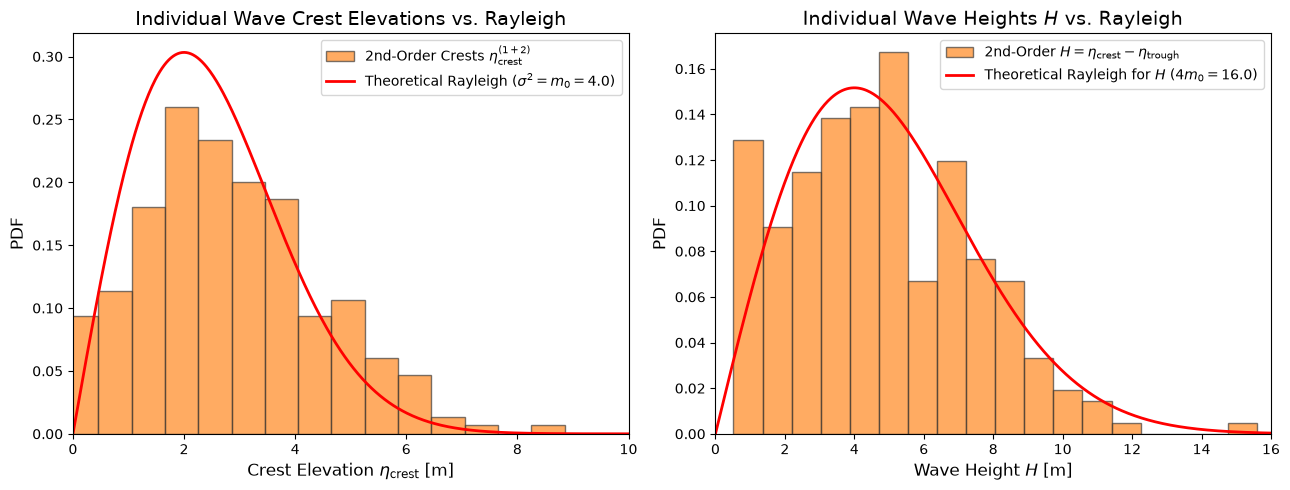

In [104]:
# --- 7. Question 5: Individual Wave Crests & Heights via scipy.signal.find_peaks ---
from scipy.signal import find_peaks

# 1. Find actual wave crests on eta_total
# prominence=0.5 ignores tiny 1-second surface ripples riding on top of main waves
peaks, _ = find_peaks(eta_total, prominence=0.5)

eta_crest_nonlin = []
H_nonlin_waves = []

# 2. Pair each crest with the lowest trough before the next crest
for i in range(len(peaks) - 1):
    idx_crest = peaks[i]
    idx_next_crest = peaks[i + 1]
    
    crest = eta_total[idx_crest]
    trough = np.min(eta_total[idx_crest:idx_next_crest])
    
    eta_crest_nonlin.append(crest)
    H_nonlin_waves.append(crest - trough)

eta_crest_nonlin = np.array(eta_crest_nonlin)
H_nonlin_waves = np.array(H_nonlin_waves)

# 3. Theoretical Rayleigh PDFs
m0 = Hs**2 / 16  # m0 = 4.0 m^2

# For crest elevation: p(eta_c) = (eta_c / m0) * exp(-eta_c^2 / (2 * m0))
crest_vals = np.linspace(0, 10, 500)
rayleigh_crest_pdf = (crest_vals / m0) * np.exp(-crest_vals**2 / (2 * m0))

# For wave height H: p(H) = (H / (4 * m0)) * exp(-H^2 / (8 * m0))
H_vals = np.linspace(0, 16, 500)
rayleigh_H_pdf = (H_vals / (4 * m0)) * np.exp(-H_vals**2 / (8 * m0))

# --- Plot Comparison ---
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Left Panel: 2nd-Order Crest Elevations vs. Rayleigh
ax[0].hist(
    eta_crest_nonlin,
    bins=20,
    density=True,
    alpha=0.65,
    color='tab:orange',
    edgecolor='#333333',
    label=r'2nd-Order Crests $\eta^{(1+2)}_{\text{crest}}$'
)
ax[0].plot(
    crest_vals,
    rayleigh_crest_pdf,
    color='red',
    linewidth=2,
    label=r'Theoretical Rayleigh ($\sigma^2 = m_0 = 4.0$)'
)
ax[0].set_title('Individual Wave Crest Elevations vs. Rayleigh', fontsize=14)
ax[0].set_xlabel(r'Crest Elevation $\eta_{\text{crest}}$ [m]', fontsize=12)
ax[0].set_ylabel('PDF', fontsize=12)
ax[0].set_xlim(0, 10)
ax[0].legend(fontsize=10)

# Right Panel: 2nd-Order Wave Heights H vs. Rayleigh
ax[1].hist(
    H_nonlin_waves,
    bins=20,
    density=True,
    alpha=0.65,
    color='tab:orange',
    edgecolor='#333333',
    label=r'2nd-Order $H = \eta_{\text{crest}} - \eta_{\text{trough}}$'
)
ax[1].plot(
    H_vals,
    rayleigh_H_pdf,
    color='red',
    linewidth=2,
    label=r'Theoretical Rayleigh for $H$ ($4m_0 = 16.0$)'
)
ax[1].set_title('Individual Wave Heights $H$ vs. Rayleigh', fontsize=14)
ax[1].set_xlabel('Wave Height $H$ [m]', fontsize=12)
ax[1].set_ylabel('PDF', fontsize=12)
ax[1].set_xlim(0, 16)
ax[1].legend(fontsize=10)

plt.tight_layout()
plt.show()


##### Stuff

In [ ]:
# # Top Floor Read
# data_top = pd.read_csv('top_floor_cleaned.csv')
# data_x3 = data_top.iloc[:, 2].to_numpy()
# data_y3 = data_top.iloc[:, 3].to_numpy()
# data_z3 = data_top.iloc[:, 4].to_numpy()

# # Second Floor Read
# data_2 = pd.read_csv('2nd_floor_cleaned.csv')
# data_x2 = data_2.iloc[:, 2].to_numpy()
# data_y2 = data_2.iloc[:, 3].to_numpy()
# data_z2 = data_2.iloc[:, 4].to_numpy()

# # First Floor Read
# data_1 = pd.read_csv('1st_floor_cleaned.csv')
# data_x1 = data_1.iloc[:, 2].to_numpy()
# data_y1 = data_1.iloc[:, 3].to_numpy()
# data_z1 = data_1.iloc[:, 4].to_numpy()

# # Ground Floor Read
# data_0 = pd.read_csv('ground_floor_cleaned.csv')
# data_x0 = data_0.iloc[:, 2].to_numpy()
# data_y0 = data_0.iloc[:, 3].to_numpy()
# data_z0 = data_0.iloc[:, 4].to_numpy()






data_top = pd.read_csv('top_floor_cleaned.csv')
data_x3 = data_top.iloc[:, 2].to_numpy()
data_y3 = data_top.iloc[:, 3].to_numpy()
data_z3 = data_top.iloc[:, 4].to_numpy()

# Second Floor Read
data_2 = pd.read_csv('2nd_floor_cleaned.csv')
data_x2 = data_2.iloc[:, 2].to_numpy()
data_y2 = data_2.iloc[:, 3].to_numpy()
data_z2 = data_2.iloc[:, 4].to_numpy()

# First Floor Read
data_1 = pd.read_csv('1st_floor_cleaned.csv')
data_x1 = data_1.iloc[:, 2].to_numpy()
data_y1 = data_1.iloc[:, 3].to_numpy()
data_z1 = data_1.iloc[:, 4].to_numpy()

# Ground Floor Read
data_0 = pd.read_csv('ground_floor_cleaned.csv')
data_x0 = data_0.iloc[:, 2].to_numpy()
data_y0 = data_0.iloc[:, 3].to_numpy()
data_z0 = data_0.iloc[:, 4].to_numpy()

Fs = 200  # 200 Hz - data sampling rate
Ts = 1 / Fs  # time interval

# Time columns (Note: t3 is preserved separately for the Power Spectrum calculation)
t3 = np.arange(0, len(data_x3)) * Ts
t2 = np.arange(0, len(data_x2)) * Ts
t1 = np.arange(0, len(data_x1)) * Ts
t0 = np.arange(0, len(data_x0)) * Ts

npts3 = len(data_x3)  # Top Floor
npts2 = len(data_x2)  # 2nd Floor
npts1 = len(data_x1)  # 1st Floor
npts0 = len(data_x0)  # Ground Floor


# Helper for MATLAB's 2^nextpow2(n)
def next_pow2(n):
    return int(2 ** np.ceil(np.log2(n)))


n3 = next_pow2(npts3)
n2 = next_pow2(npts2)
n1 = next_pow2(npts1)
n0 = next_pow2(npts0)

# FFT (Normalized with Fs to compare with SeismoSignal results)
FFT_data_x3 = np.fft.fft(data_x3, n3) / Fs
FFT_data_x2 = np.fft.fft(data_x2, n2) / Fs
FFT_data_x1 = np.fft.fft(data_x1, n1) / Fs
FFT_data_x0 = np.fft.fft(data_x0, n0) / Fs

freq3 = (Fs / 2) * np.linspace(0, 1, n3 // 2 + 1)
freq2 = (Fs / 2) * np.linspace(0, 1, n2 // 2 + 1)
freq1 = (Fs / 2) * np.linspace(0, 1, n1 // 2 + 1)
freq0 = (Fs / 2) * np.linspace(0, 1, n0 // 2 + 1)

FFT_data_x3 = np.abs(FFT_data_x3[: len(freq3)])
FFT_data_x2 = np.abs(FFT_data_x2[: len(freq2)])
FFT_data_x1 = np.abs(FFT_data_x1[: len(freq1)])
FFT_data_x0 = np.abs(FFT_data_x0[: len(freq0)])

# Figure 1: Fourier Amplitude Spectra
plt.figure(1)
plt.plot(freq3, FFT_data_x3, 'b', label='Top Floor')
plt.plot(freq2, FFT_data_x2, 'r', label='2nd Floor')
plt.plot(freq1, FFT_data_x1, 'y', label='1st Floor')
plt.plot(freq0, FFT_data_x0, 'g', label='Ground Floor')
plt.title('Fourier Amplitude Spectra')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Fourier Amplitude')
plt.legend()
plt.grid(True)

# Export FFT_x to Excel
df_fft = pd.DataFrame({'Frequency_Hz': freq3, 'FFT_Amplitude': FFT_data_x3})
df_fft.to_excel('FFT_x.xlsx', sheet_name='Sheet1', index=False, header=False)

# Power Spectrum - SeismoSignal
Arms_x = ((1 / np.max(t3)) * np.trapezoid(data_x3**2, t3)) ** 0.5
psd3 = (1 / (np.pi * (Arms_x**2) * np.max(t3))) * (FFT_data_x3**2)

# Figure 2: Power Spectra
plt.figure(2)
plt.plot(freq3, psd3)
plt.title('Power Spectra')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.grid(True)

# Export PSD_x to Sheet3 of Excel
df_psd = pd.DataFrame({'Frequency_Hz': freq3, 'PSD': psd3})
with pd.ExcelWriter('PSD_x.xlsx', engine='openpyxl') as writer:
    # Create empty placeholder sheets to match MATLAB's sheet index 3
    pd.DataFrame().to_excel(writer, sheet_name='Sheet1', index=False)
    pd.DataFrame().to_excel(writer, sheet_name='Sheet2', index=False)
    df_psd.to_excel(writer, sheet_name='Sheet3', index=False, header=False)

plt.show()
